In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from clustering.utils import generate_data, SpaceTimeSVD, ClusteringCPQR

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 


In [2]:
np.random.seed(0)

In [59]:
series, truth = generate_data(
    n_timepoints=1_000,
    n_components=10,
    noise=5,
    n_pixels=(3, 16),
    n_pixels_bg=100,
)

RFBOutputContext()

JupyterWgpuCanvas(css_height='500px', css_width='700px')
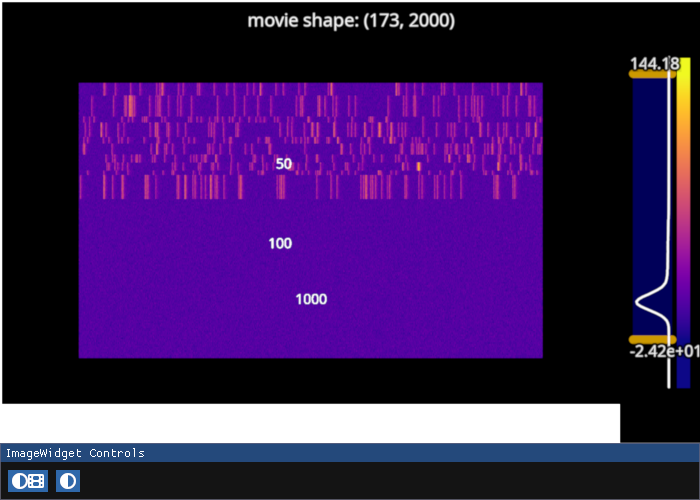

In [60]:
iw_series = fpl.ImageWidget(
    series, 
    figure_kwargs={"size": (700, 500)},
    names=[f"movie shape: {series.shape}"],
)
iw_series.figure[0, 0].camera.maintain_aspect = False
iw_series.show()

In [61]:
st_svd = SpaceTimeSVD(series, w=16)
st_svd.compute()

Computing F, P


100%|█████████████████████████████████████████████████████████████████████| 173/173 [00:00<00:00, 9596.17it/s]


(173, 2000)
(1384, 1984)


100%|████████████████████████████████████████████████████████████████████| 173/173 [00:00<00:00, 18641.35it/s]

computing H
Computing Hp
computimng svd of Hp


RFBOutputContext()

JupyterWgpuCanvas()
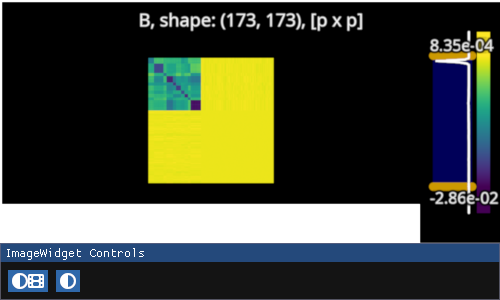

In [62]:
iw_adj = fpl.ImageWidget(
    st_svd.adjacency, 
    cmap="viridis",
    names=[f"B, shape: {st_svd.adjacency.shape}, [p x p]"]
)
iw_adj.show()

In [63]:
clustering = ClusteringCPQR(st_svd.adjacency, k=11)

In [64]:
np.linalg.norm(st_svd.adjacency - st_svd.adjacency.T, ord="fro") / np.linalg.norm(clustering.B)

np.float64(0.15154523661472086)

In [65]:
clustering.Qk.T.shape

(11, 173)

In [66]:
np.linalg.norm(clustering.Qk.T, axis=0, ord=2)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1.])

In [13]:
import pygfx
from wgpu.gui.jupyter import WgpuCanvas

canvas = WgpuCanvas()
renderer = pygfx.WgpuRenderer(target=canvas, blend_mode="weighted_plus")

fig = fpl.Figure(
    cameras="3d", 
    controller_types="orbit", 
    size=(1000, 800),
    renderer=renderer,
    canvas=canvas
)

spaceplot = fig[0, 0]

spaceplot.add_scatter(clustering.Qk, colors="r", name="Qk", sizes=15, alpha=0.2)

spaceplot.axes.intersection = (0, 0, 0)
fig.canvas.quality = 100
fig.show(sidecar=True)

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:276: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size


In [67]:
clustering.P

array([[-3.90663500e-02, -3.72983419e-02, -5.67810682e-03,
        -2.20323913e-02, -3.38572464e-02,  2.50324725e-02,
         1.16285648e-02,  9.79347016e-03,  1.12658664e-02,
        -9.97701698e-01,  3.56149470e-02],
       [ 1.70782768e-01, -1.66719301e-01,  1.33141979e-01,
         6.54955886e-02, -5.50278966e-02,  1.06563752e-02,
         2.49724903e-01,  9.08304024e-02, -6.63721762e-04,
         7.17907752e-03, -9.13941689e-01],
       [ 2.08785737e-01, -8.62909246e-02, -6.41268334e-01,
        -3.82750742e-01,  1.15169127e-01, -1.41316730e-02,
         2.01788466e-01,  1.10781233e-01,  5.72059370e-01,
         2.61243921e-02,  2.10831513e-02],
       [ 4.24563824e-01,  1.80390960e-01, -2.93271973e-01,
        -3.62016167e-01, -8.28544430e-03,  1.27099718e-01,
         7.60145807e-02,  3.63067827e-02, -7.30960640e-01,
         1.38071485e-02,  5.75913284e-05],
       [ 2.71509218e-01, -3.62136940e-02,  6.26613094e-01,
        -6.69896908e-01, -6.29895229e-03, -3.93579119e-02,
  

In [68]:
clustering.W.shape

(11, 11)

In [69]:
clustering.transformed.shape

(11, 173)

In [17]:
spaceplot.add_scatter(clustering.W.T, colors="b", name="W", sizes=15, alpha=0.8)
spaceplot.add_scatter(clustering.transformed.T, colors="g", name="transform", sizes=15, alpha=0.2)

'transform': ScatterGraphic @ 0x7f2858561890

In [18]:
from fastplotlib.graphics._axes import Axes

In [19]:
if clustering.k == 2:
    basis_W = np.array([
        [*clustering.W.T[0], 0],
        [*clustering.W.T[1], 0],
        [0., 0., 1.]
    ])

elif clustering.k == 3:
    basis_W = np.array([
        clustering.W.T[0],
        clustering.W.T[1],
        clustering.W.T[2]
    ])

axes_W = Axes(fig[0, 0], intersection=(0, 0, 0), basis=basis_W)
axes_W.colors = ("b", "b", "b")

spaceplot.scene.add(axes_W.world_object)
spaceplot.add_animations(axes_W.update_using_camera)

fig[0, 0].axes.colors = ("g", "g", "g")

In [70]:
from ipywidgets import VBox

In [71]:
clustering.transformed.argmax(axis=0)

array([ 0,  0,  0,  0,  0,  0,  0,  0,  5,  5,  5,  5,  5,  5,  5,  5,  5,
        5,  5,  5,  5,  8,  8,  8,  8,  6,  6,  6,  6,  6,  6,  6,  6,  6,
        2,  2,  2,  2,  4,  4,  4,  4,  4,  4,  4,  3,  3,  3,  3,  3,  7,
        7,  7,  7,  7, 10, 10, 10,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,
        9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,
        9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,
        9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,
        9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,
        9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,
        9,  9,  9])

In [72]:
clustering.transformed.shape

(11, 173)

In [73]:
iw_movie = fpl.ImageWidget(series, figure_kwargs={"size": (1200, 600)})
iw_movie.figure.show(maintain_aspect=False)

iw = fpl.ImageWidget(
    [clustering.Qk, clustering.W, clustering.transformed.T], 
    names=["Qk", "W", "transform"], 
    figure_shape=(1, 3),
    figure_kwargs={"controller_ids": [[0, 1, 2]], "size": (1200, 350)},
)
iw.figure["transform"].set_title("W.T x Qk.T")
iw.cmap = ["bwr", "bwr", "viridis"]
iw.figure.show(maintain_aspect=False)

iw_movie.figure[0, 0].add_image(
    data=np.column_stack([clustering.transformed.argmax(axis=0)]*2),
    cmap="tab20",
    offset=(-45, 0, 0),
    name="cluster-labels"
)
iw_movie.figure[0, 0]["cluster-labels"].world_object.local.scale_x = 25

def update_movie(*args):
    movie = generate_data(
        n_timepoints=1_000, 
        n_components=slider_n_components.value,
        noise=slider_noise.value,
        n_pixels=slider_n_pixels.value,
        n_pixels_bg=slider_n_bg_pixels.value,
    )

    global st_svd
    
    st_svd = SpaceTimeSVD(movie, w=16)
    st_svd.compute()

    iw_movie.set_data(movie)
    iw_movie.figure[0, 0].auto_scale(maintain_aspect=False)

def update_clustering(*args):
    global st_svd
    
    clustering = ClusteringCPQR(st_svd.adjacency, k=slider_k.value)

    iw.set_data([clustering.Qk, clustering.W, clustering.transformed.T])
    
    for subplot in iw.figure:
        subplot.auto_scale(maintain_aspect=False)

    iw.cmap = ["bwr", "bwr", "viridis"]

    iw_movie.figure[0, 0].delete_graphic(iw_movie.figure[0, 0]["cluster-labels"])
    
    iw_movie.figure[0, 0].add_image(
        data=np.column_stack([clustering.transformed.argmax(axis=0)]*2),
        cmap="tab20",
        offset=(-45, 0, 0),
        name="cluster-labels"
    )
    iw_movie.figure[0, 0]["cluster-labels"].world_object.local.scale_x = 25

VBox([iw_movie.show(), iw.show()])

RFBOutputContext()

RFBOutputContext()

In [24]:
selector_movie = iw_movie.managed_graphics[0].add_linear_selector(axis="y")
selector_Qk = iw.figure["Qk"]["image_widget_managed"].add_linear_selector(axis="y")
selector_transform = iw.figure["transform"]["image_widget_managed"].add_linear_selector(axis="y")
selectors = [selector_movie, selector_Qk, selector_transform]

In [25]:
class IndexStore:
    def __init__(self):
        self.index: int = None

    def set_index(self, new_index: int, source_graphic: fpl.LinearSelector | fpl.ScatterGraphic):
        self._set_points(new_index)
        self._set_linear_selectors(new_index, source_graphic)

    def _set_points(self, index: int):
        # reset colors
        spaceplot["Qk"].colors = (1, 0, 0, 0.2)
        spaceplot["Qk"].sizes = 15
        
        spaceplot["transform"].colors = (0, 1, 0, 0.2)
        spaceplot["transform"].sizes = 15
        
        # set colors and size
        spaceplot["Qk"].colors[index] = (1, 0.35, 0.35, 0.8)
        spaceplot["Qk"].sizes[index] = 25
        
        spaceplot["transform"].colors[index] = (0.35, 1, 0.35, 0.8)
        spaceplot["transform"].sizes[index] = 25

    def _set_linear_selectors(self, index: int, source_graphic):
        with fpl.pause_events(*selectors):
            for selector in selectors:
                if source_graphic is selector:
                    continue
                selector.selection = index

    def _scatter_callback(self, ev):
        index = ev.pick_info["vertex_index"]
        self.set_index(index, ev.graphic)
    
    def register_scatter(self, graphic: fpl.ScatterGraphic):
        graphic.add_event_handler(self._scatter_callback, "click")

    def _linear_selector_callback(self, ev):
        index = ev.get_selected_index()
        self.set_index(index, ev.graphic)
    
    def register_linear_selector(self, selector: fpl.LinearSelector):
        selector.add_event_handler(self._linear_selector_callback, "selection")

In [26]:
index_store = IndexStore()

index_store.register_scatter(spaceplot["Qk"])
index_store.register_scatter(spaceplot["transform"])

index_store.register_linear_selector(selector_movie)
index_store.register_linear_selector(selector_Qk)
index_store.register_linear_selector(selector_transform)

In [25]:
spaceplot["Qk"].clear_event_handlers()
spaceplot["transform"].clear_event_handlers()

In [26]:
[s.clear_event_handlers() for s in selectors]

[None, None, None]